In [2]:
!pip install seaborn pandas matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 2.8 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/9.3 MB 2.0 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.3 MB 1.6 MB/s eta 0:00:06
   ----- ---------------------------------- 1.3/9.3 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/9.3 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.3 MB 2.2 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.3 MB 2.2 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.3 MB 2.2 MB/s eta 0:00:03
   -------------------- ------------------- 4.7/9.3 MB 2.3 MB/s eta 0:00:03
   ---------------------- ----------------- 5.2/9.3 MB 2.3 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 2.4 MB/s eta 0:00:02
   ----------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import seaborn as sns
# load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [4]:
print("missing values per column:")
print(df.isnull().sum())

missing values per column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
df['tip'] = df['tip'].fillna(df['tip'].median())
df['tolls'] = df['tolls'].fillna(df['tolls'].median())
df['total'] = df['total'].fillna(df['total'].median())
df['fare'] = df['fare'].fillna(df['fare'].median())
df['distance'] = df['distance'].fillna(df['distance'].median())
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
print("after imputation:")
print(df.isnull().sum())

after imputation:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [8]:
df = df.dropna(subset=['pickup', 'dropoff'])
print("after remove:")
print(df.isnull().sum())
print(f"after shape: {df.shape}")



after remove:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
after shape: (6433, 14)


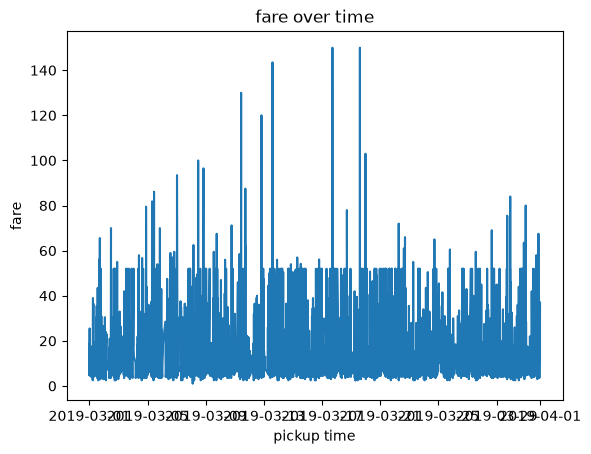

In [16]:
import matplotlib.pyplot as plt

df = df.sort_values('pickup')
plt.plot(df['pickup'],df['fare'])
plt.title('fare over time')
plt.xlabel('pickup time')
plt.ylabel('fare')
plt.show()


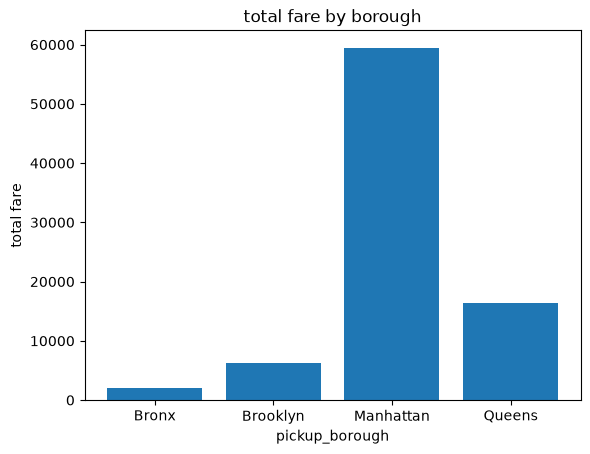

In [19]:
import matplotlib.pyplot as plt
data = df.groupby('pickup_borough')['fare'].sum()
plt.bar(data.index,data.values)
plt.xlabel('pickup_borough')
plt.ylabel('total fare')
plt.title('total fare by borough')
plt.show()


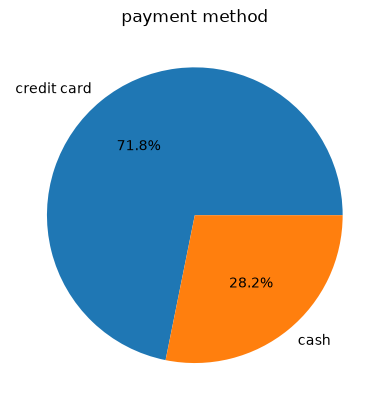

In [20]:
data = df['payment'].value_counts()
plt.pie(data.values,labels=data.index, autopct='%1.1f%%')
plt.title('payment method')
plt.show()

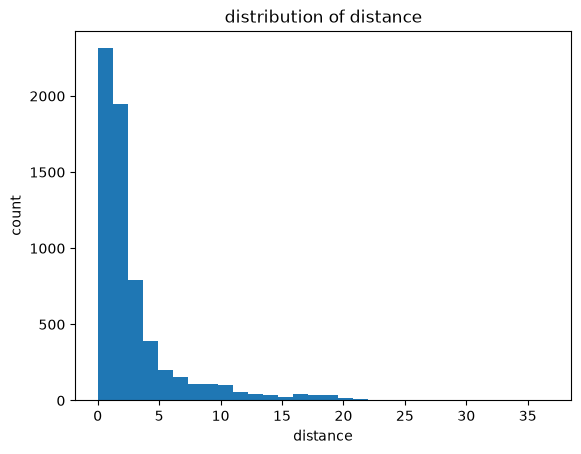

In [21]:
import matplotlib.pyplot as plt
plt.hist(df['distance'],bins=30)
plt.title('distribution of distance')
plt.xlabel('distance')
plt.ylabel('count')
plt.show()

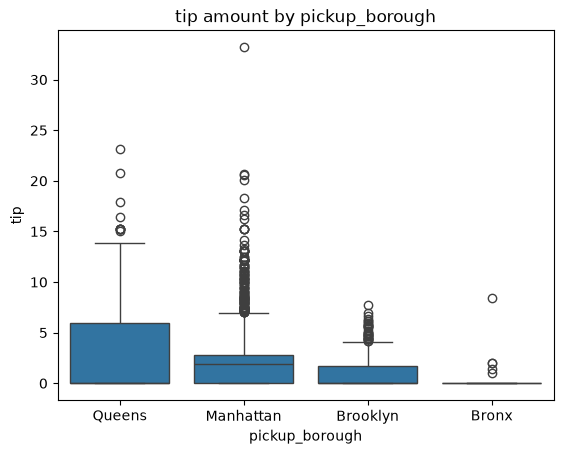

In [22]:
import seaborn as sns
sns.boxplot(x='pickup_borough',y='tip', data=df)
plt.title('tip amount by pickup_borough')
plt.show()

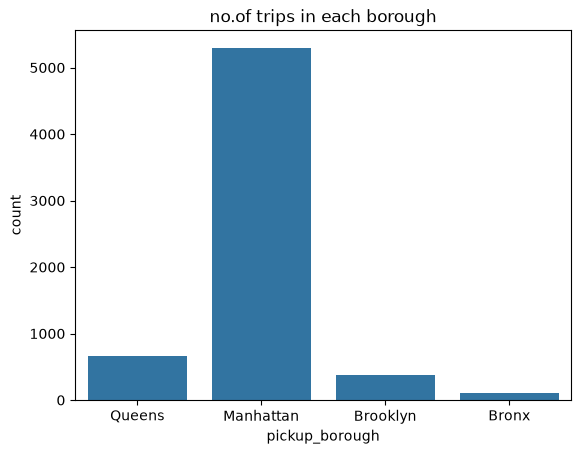

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x='pickup_borough',data=df)
plt.title('no.of trips in each borough')
plt.show()

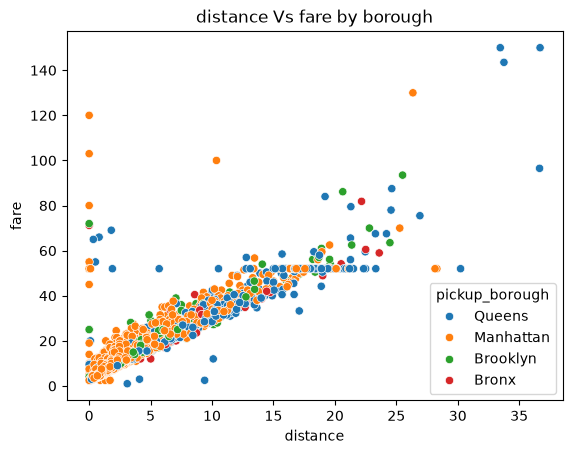

In [26]:
sns.scatterplot(x='distance',y='fare', hue='pickup_borough',data=df)
plt.title('distance Vs fare by borough')
plt.show()

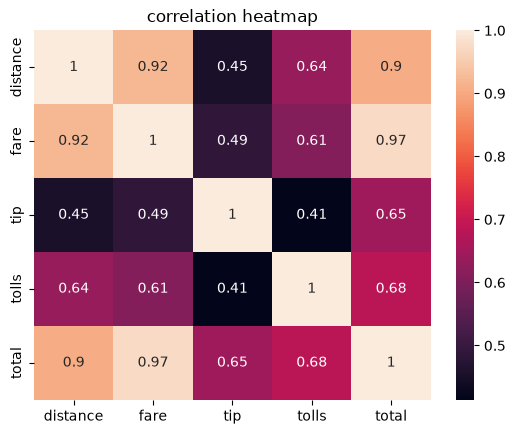

In [30]:
corr = df[['distance','fare','tip','tolls','total']].corr()
sns.heatmap(corr,annot=True)
plt.title('correlation heatmap')
plt.show()


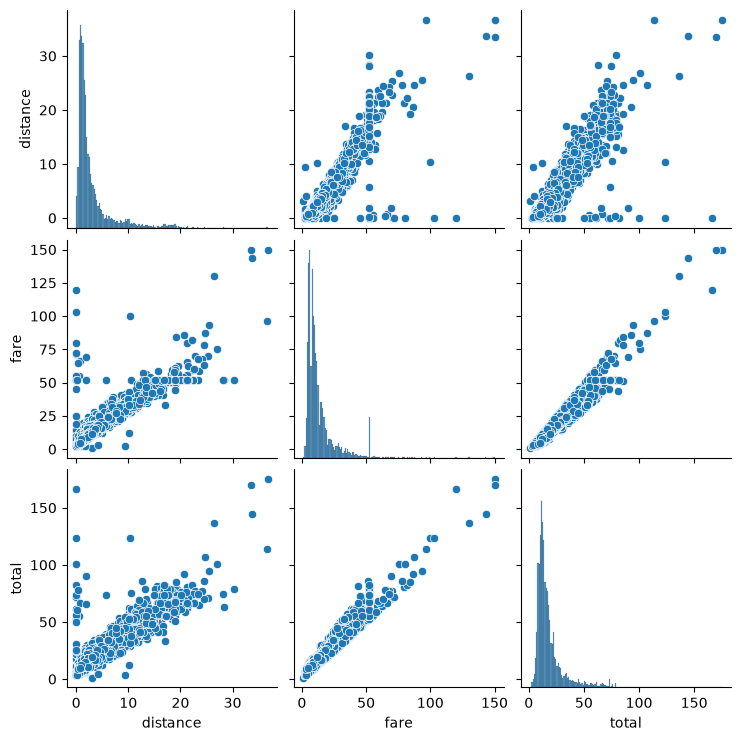

In [31]:
sns.pairplot(df[['distance','fare','total','pickup_borough']])
plt.show()

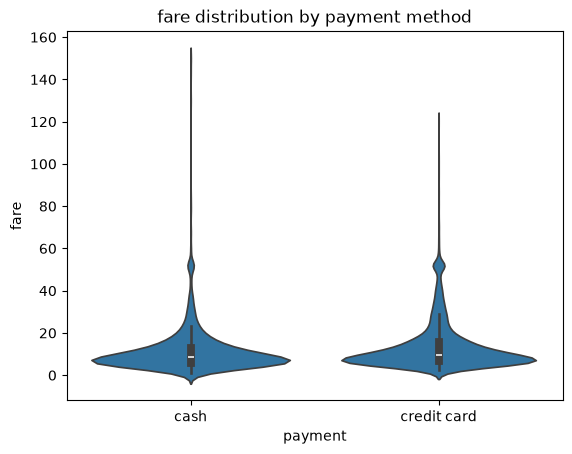

In [32]:
sns.violinplot(x='payment',y='fare', data=df)
plt.title('fare distribution by payment method')
plt.show()